<a href="https://colab.research.google.com/github/NastaranTork/stochastic-processes-lab/blob/main/02_train_dispatch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Train dispatch: when should the train leave?

**Setup.** Passengers arrive at a station as a Poisson process with rate λ = 2 per minute. Each passenger waits from arrival until the train departs at time t. The train leaves every t minutes, and the platform is empty after each departure.

**Claim.** The expected total waiting time of all passengers in one cycle is E[W] = λt²/2.

**Prediction.** For λ = 2 and t = 10, E[W] = 2 × 10² / 2 = 100 passenger-minutes.

**Plan.**
1. Check the claim by simulation.
2. Build a cost per minute that trades off departure cost against waiting cost.
3. Find the departure interval that minimizes it.

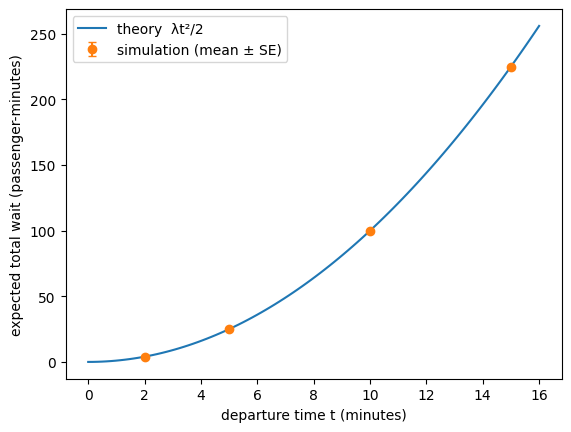

In [20]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(8532)

def simulate_pp(lam, T, rng):
  arrivals = []
  clock = 0
  wait = 0
  while True:
    gap = rng.exponential(scale = 1/lam)
    clock += gap
    if clock > T:
      break
    arrivals.append(clock)
    wait += T - clock
  return arrivals, wait

def Expected_W(rng, lam, T, runs= 20000):

  waits = []
  for run in range(runs):
    a, w = simulate_pp(lam, T, rng)
    waits.append(w)

  mean = np.mean(waits)
  standard_error = np.std(waits, ddof=1) / np.sqrt(len(waits))
  return mean, standard_error

lam = 2
departure_times = [2, 5, 10, 15]
means, ses = [], []
for t in departure_times:
  m, se = Expected_W(rng, lam, t)
  means.append(m)
  ses.append(se)

grid = np.linspace(0, 16, 100)

plt.plot(grid, lam * grid**2 / 2, label="theory  λt²/2")
plt.errorbar(departure_times, means, yerr=ses, fmt="o", capsize=3, label="simulation (mean ± SE)")
plt.xlabel("departure time t (minutes)")
plt.ylabel("expected total wait (passenger-minutes)")
plt.legend()
plt.show()


**Result.** The simulated mean waiting time matches λt²/2 at t = 2, 5, 10 and 15. At t = 10 the simulated mean is 100.00 with a standard error of 0.18, well within two standard errors of the prediction. The standard error grows with t because longer windows collect more passengers who each wait longer, so total waiting varies more from run to run.

## Minimizing the cost per minute

**Cost model (illustrative numbers).** Each departure costs K = 60 dollars. Each passenger-minute of waiting costs c = 0.5 dollars. One cycle lasts t minutes and costs, on average, K + c·λt²/2. Because every cycle starts from an empty platform, all cycles are statistically identical, so the long-run cost per minute is

g(t) = (K + c·λt²/2) / t = K/t + cλt/2

The first term shrinks as t grows (fewer departures). The second term grows with t (longer waits). The best interval balances the two.

cost per minute for a departure interval of 10 is 10.991140511123195


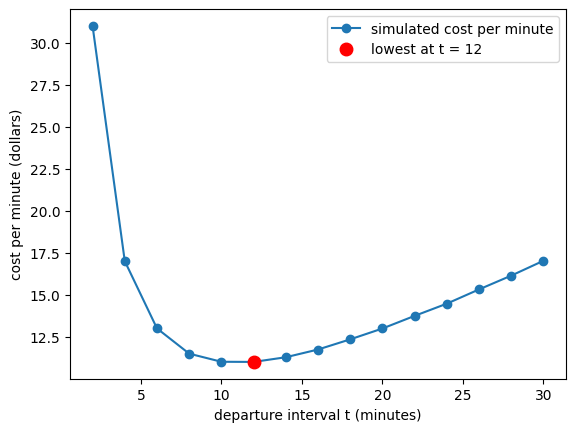

In [25]:

K = 60    # Fixed Departure Cost ($ per departure)
c = 0.5   # Cost of waiting      ($ per passenger-minutes)
T = 10
lam = 2
def cost_rate(T, lam, K = 60, c = 0.5):
  wait_m, _ = Expected_W(rng, lam, T)
  cost_per_cycle = K + c * wait_m
  cycle_length = T
  cost_per_min = cost_per_cycle / T

  return cost_per_min

cost_per_min = cost_rate(T, lam, K, c)
print("cost per minute for a departure interval of", T, "is", cost_per_min)

ts = list(range(2, 32, 2))
rates = []
for t in ts:
    rates.append(cost_rate(t, lam))

best = np.argmin(rates)

plt.plot(ts, rates, "o-", label="simulated cost per minute")
plt.plot(ts[best], rates[best], "ro", markersize=9, label=f"lowest at t = {ts[best]}")
plt.xlabel("departure interval t (minutes)")
plt.ylabel("cost per minute (dollars)")
plt.legend()
plt.show()


## Conclusion

The simulated cost per minute falls steeply for short intervals, bottoms out near t = 12 minutes at about 11 dollars per minute, and then rises slowly. Leaving too often wastes money on departures, and leaving too rarely makes passengers wait too long.

The curve is flat near the minimum. On the grid, t = 10 and t = 12 cost almost the same, so a few minutes early or late changes the cost very little. Sending the train every 2 minutes costs about 31 dollars per minute, which is nearly three times the minimum, so the shortest intervals are by far the most expensive mistake.

**Analytical check.** Setting g'(t) = 0 gives t* = [your formula]. With K = 60, c = 0.5 and λ = 2, this is t* = [your number] minutes, which agrees with the simulated minimum within the grid resolution.

**Sensitivity.** If arrivals double, t* [shrinks or grows] by a factor of [your answer]. If the departure cost doubles, t* [shrinks or grows] by a factor of [your answer].